## Two-Optimizers Fine-Tuning

In [ ]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [3]:
# Import necessary libraries
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.use('seaborn-v0_8')

In [4]:
# Set random seed for reproducibility across runs
seed_everything(42)

In [7]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",
    train_ratio = 0.98,  # 🔥 FIX: Was None! Must be 0.98 for 98/2 split
    batchsize = 64,
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

print(f"✅ Data loaded")
print(f"   Train batches: {len(train_dataloader)}")
print(f"   Val batches: {len(val_dataloader) if val_dataloader else 0}")

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

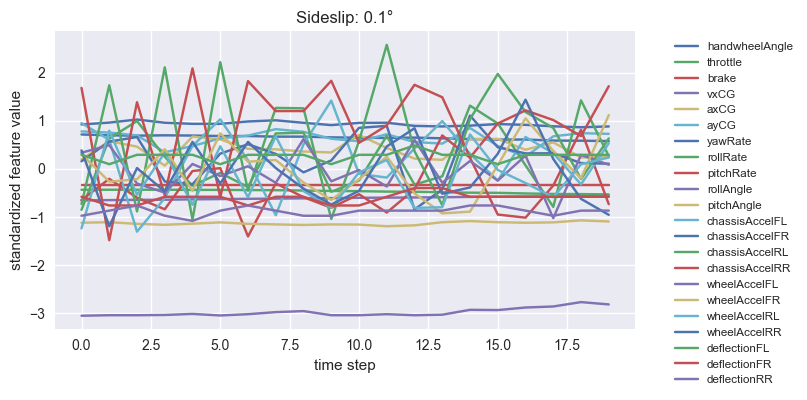

In [8]:
# Get one batch to check dimensions
X, y = next(iter(train_dataloader))

plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [9]:
class RNN(nn.Module):
    def __init__(self, input_size, output_size=1, rnn_units=28, fc_units=28, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=1, nonlinearity=rnn_nonlinearity, batch_first=True)
        
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        
        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        
        self.activation_fct = activation_fct
 
    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)
        x = x[:, -1, :]
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

input_size = X.shape[2]
rnn_units = 64
fc_units = 64
output_size = 1
lr = 0.0003

model = RNN(
    input_size=input_size, 
    output_size=output_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
    dropout=[0.0, 0.0, 0.0]
).to(device)

criterion = nn.L1Loss()

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu
Model parameters: 9,857


In [ ]:
FEW_MIN = -14.9
FEW_MAX =  11.6

def extract_few_shot(loader, low=FEW_MIN, high=FEW_MAX):
    Xf, yf = [], []
    for X, y in loader:
        mask = ((y >= low) & (y <= high)).reshape(-1)
        if mask.any():
            Xf.append(X[mask])
            yf.append(y[mask])

    Xf = torch.cat(Xf, dim=0)
    yf = torch.cat(yf, dim=0)

    print("Few-shot samples:", len(yf))
    return Xf, yf

X_few, y_few = extract_few_shot(train_dataloader)

few_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X_few, y_few),
    batch_size=64, shuffle=True
)


Few-shot samples: 3732


In [13]:
optimizer_A = torch.optim.Adam(model.parameters(), lr=3e-4)
optimizer_B = torch.optim.Adam(model.parameters(), lr=1e-5)  # smaller LR


In [14]:
num_epochs = 35
best_loss = np.inf
best_epoch = -1

for epoch in range(num_epochs):

    # ===============================
    # 🔥 STAGE 1 — NORMAL TRAINING
    # ===============================
    model.train()
    running_loss = 0

    for X, y in train_dataloader:
        X, y = X.to(device), y.to(device).reshape(-1, 1)

        optimizer_A.zero_grad()
        pred = model(X)
        loss = criterion(pred, y)
        loss.backward()
        optimizer_A.step()

        running_loss += loss.item()

    avg_train = running_loss / len(train_dataloader)


    # ===============================
    # 🔥 STAGE 2 — FEW-SHOT FINE-TUNE
    # ===============================
    ft_loss_sum = 0
    model.train()

    for X, y in few_loader:
        X, y = X.to(device), y.to(device).reshape(-1, 1)

        optimizer_B.zero_grad()
        pred = model(X)

        # Very gentle correction
        loss_few = criterion(pred, y)

        loss_few.backward()
        optimizer_B.step()

        ft_loss_sum += loss_few.item()

    avg_ft = ft_loss_sum / len(few_loader)


    # ===============================
    # VALIDATION
    # ===============================
    model.eval()
    running_val_loss = 0
    with torch.no_grad():
        for X, y in val_dataloader:
            X, y = X.to(device), y.to(device).reshape(-1, 1)
            running_val_loss += criterion(model(X), y).item()

    avg_val = running_val_loss / len(val_dataloader)


    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train={avg_train:.4f} | "
          f"FewTune={avg_ft:.4f} | "
          f"Val={avg_val:.4f}", end="")

    # Save best model
    if avg_val < best_loss:
        best_loss = avg_val
        best_epoch = epoch
        torch.save(model.state_dict(), "best_two_opt.pth")
        print("  ✓ Saved (best)")
    else:
        print("")


Epoch 01/35 | Train=0.2795 | FewTune=0.0917 | Val=0.2093  ✓ Saved (best)
Epoch 02/35 | Train=0.1880 | FewTune=0.0859 | Val=0.1756  ✓ Saved (best)
Epoch 03/35 | Train=0.1720 | FewTune=0.0829 | Val=0.1642  ✓ Saved (best)
Epoch 04/35 | Train=0.1634 | FewTune=0.0813 | Val=0.1678
Epoch 05/35 | Train=0.1581 | FewTune=0.0813 | Val=0.1618  ✓ Saved (best)
Epoch 06/35 | Train=0.1543 | FewTune=0.0790 | Val=0.1490  ✓ Saved (best)
Epoch 07/35 | Train=0.1512 | FewTune=0.0765 | Val=0.1571
Epoch 08/35 | Train=0.1483 | FewTune=0.0764 | Val=0.1574
Epoch 09/35 | Train=0.1461 | FewTune=0.0746 | Val=0.1556
Epoch 10/35 | Train=0.1442 | FewTune=0.0783 | Val=0.1542
Epoch 11/35 | Train=0.1425 | FewTune=0.0765 | Val=0.1395  ✓ Saved (best)
Epoch 12/35 | Train=0.1400 | FewTune=0.0809 | Val=0.1314  ✓ Saved (best)
Epoch 13/35 | Train=0.1392 | FewTune=0.0747 | Val=0.1493
Epoch 14/35 | Train=0.1374 | FewTune=0.0779 | Val=0.1461
Epoch 15/35 | Train=0.1365 | FewTune=0.0748 | Val=0.1522
Epoch 16/35 | Train=0.1354 | FewT

In [15]:
model.load_state_dict(torch.load("best_two_opt.pth"))
print(f"Loaded best model from epoch {best_epoch+1}")


Loaded best model from epoch 30


In [18]:
# Load complete training data for visualization
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,
    load_anonymized_data=False
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [19]:
import plotly.graph_objects as go

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Training set MAE: {total_loss/(step+1):.5f}")
    
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions (Training Set)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()



Training set MAE: 0.12100


In [20]:
print("\nLoading test data...")
test_dataloader = load_test_data(
    test_path = "../../datasets_challenge/test",
    batchsize = 64,
    pipeline = pipeline, 
    load_anonymized_data=True
)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [21]:
# Generate test predictions
model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)
print(f"Test predictions: {len(test_preds)} samples")
print(f"Range: [{test_preds.min():.3f}, {test_preds.max():.3f}]")
print(f"Mean:  {test_preds.mean():.3f}")
print(f"Std:   {test_preds.std():.3f}")

Test predictions: 49328 samples
Range: [-9.285, 9.639]
Mean:  0.037
Std:   1.437


In [22]:
# Save predictions
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv("predictions_two optimizer.csv", index=False)

print(f"\n" + "="*80)
print(f"✅ Predictions saved to 'predictions_two optimizer.csv'")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for Kaggle submission!")
print("="*80)


✅ Predictions saved to 'predictions_two optimizer.csv'
   Total samples: 49328
   Ready for Kaggle submission!
